# CIE 2 – Activity 2: Binary Classification using Logistic Regression
**Course:** Regression and Classification Algorithms  
**Unit:** II – Classification & Logistic Regression  
**Student:** Samiksha Thakre  
**College:** Zeal College of Engineering and Research, Narhe, Pune  
**Academic Year:** 2026–27  

## 1. Problem statement and professional context
I am working as a data scientist supporting a health-screening research programme. The objective is to classify a breast tumour record as **malignant** or **benign** from numerical measurements. A false negative (a malignant case classified as benign) is especially serious because it may delay further assessment. This model is an educational demonstration only and must never replace clinical assessment.

**Positive class:** malignant.  
**Negative class:** benign.  
**Model:** Logistic Regression.  
**Success criteria:** evaluate confusion matrix, accuracy, precision, recall, specificity, F1-score and ROC-AUC; compare with a majority-class baseline; study thresholds 0.3, 0.5 and 0.7.

## 2. Dataset and source
- Dataset: Wisconsin Diagnostic Breast Cancer dataset included in scikit-learn.
- Source/documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
- Number of records: 569; numerical features: 30; target classes: malignant and benign.
- The original scikit-learn target encoding is 0 = malignant and 1 = benign. For this activity, I explicitly remap the target so that **1 = malignant (positive)** and **0 = benign (negative)**.
- Only the provided numerical measurements are used; no identifier is used as a feature.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, classification_report,
    RocCurveDisplay, ConfusionMatrixDisplay)

RANDOM_STATE = 42
raw = load_breast_cancer(as_frame=True)
X = raw.data.copy()
# Positive class is malignant (1); negative class is benign (0).
y = (raw.target == 0).astype(int)
df = X.copy(); df["target_malignant"] = y
print("Python:", sys.version.split()[0], "| scikit-learn:", sklearn.__version__)
print("Dataset shape:", df.shape)
print("Class mapping: 1 = malignant, 0 = benign")
display(df.head())

Python: 3.13.5 | scikit-learn: 1.8.0
Dataset shape: (569, 31)
Class mapping: 1 = malignant, 0 = benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target_malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 3. Inspect data quality and class balance
Check data types, descriptive statistics, missing values, duplicate rows and class counts. The class distribution plot shows whether a majority-class baseline could appear strong even without learning useful patterns.

,dtype
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64
mean compactness,float64
mean concavity,float64
mean concave points,float64
mean symmetry,float64
mean fractal dimension,float64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Missing values:


,missing_count
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Duplicate rows: 0
Class counts (0=benign, 1=malignant):


,count
target,
Benign (0),357
Malignant (1),212


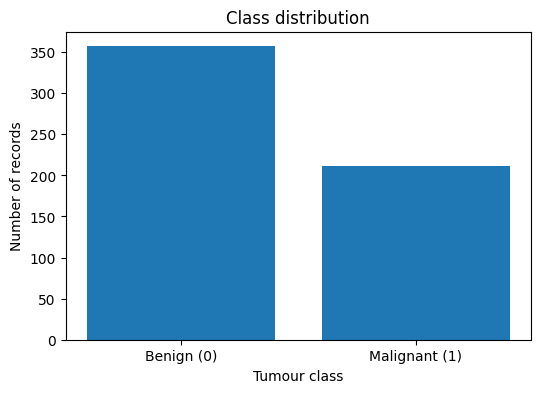

In [2]:
display(df.dtypes.to_frame("dtype"))
display(df.describe().T)
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", int(df.duplicated().sum()))
class_counts = y.value_counts().sort_index()
print("Class counts (0=benign, 1=malignant):")
display(class_counts.rename(index={0:"Benign (0)", 1:"Malignant (1)"}).to_frame("count"))

plt.figure(figsize=(6,4))
plt.bar(["Benign (0)", "Malignant (1)"], [class_counts.get(0,0), class_counts.get(1,0)])
plt.title("Class distribution"); plt.xlabel("Tumour class"); plt.ylabel("Number of records")
plt.show()

## 4. Feature preparation and stratified split
All selected features are numerical. The pipeline fits StandardScaler on the training data only, then applies the learned transformation to test data. Stratification preserves approximately the same class proportions in both sets.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training records:", len(X_train), "| Test records:", len(X_test))
print("Training class counts:", y_train.value_counts().sort_index().to_dict())
print("Test class counts:", y_test.value_counts().sort_index().to_dict())

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)
print("Model settings: StandardScaler + LogisticRegression(max_iter=5000)")

Training records: 455 | Test records: 114
Training class counts: {0: 285, 1: 170}
Test class counts: {0: 72, 1: 42}
Model settings: StandardScaler + LogisticRegression(max_iter=5000)


## 5. Why Logistic Regression?
Linear Regression predicts an unrestricted numeric value, so its output can be below 0 or above 1 and is not naturally a class probability. Logistic Regression applies the sigmoid function to a linear score:

\[
p = \frac{1}{1+e^{-z}}
\]

where \(z=b_0+b_1x_1+\cdots+b_px_p\). The probability lies between 0 and 1. A decision threshold converts the probability into a class label. The default threshold is 0.5, but the most appropriate threshold depends on the relative cost of false positives and false negatives.

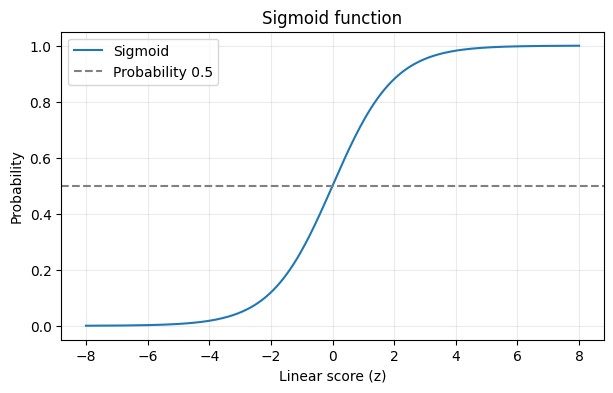

In [4]:
z = np.linspace(-8, 8, 300)
sigmoid = 1 / (1 + np.exp(-z))
plt.figure(figsize=(7,4))
plt.plot(z, sigmoid, label="Sigmoid")
plt.axhline(0.5, color="gray", linestyle="--", label="Probability 0.5")
plt.xlabel("Linear score (z)"); plt.ylabel("Probability")
plt.title("Sigmoid function"); plt.legend(); plt.grid(alpha=0.25); plt.show()

## 6. Model coefficients and predicted probabilities
The fitted coefficients are shown with their feature names. A positive coefficient increases the model's log-odds for the positive class (malignant), while a negative coefficient decreases them, holding other features fixed. Because inputs are standardised, each coefficient corresponds to a one-standard-deviation feature change.

In [5]:
logit = model.named_steps["logistic"]
coef_table = pd.DataFrame({"feature": X.columns, "coefficient": logit.coef_[0]})
display(coef_table.sort_values("coefficient", key=lambda s: s.abs(), ascending=False))
print("Intercept:", logit.intercept_[0])

proba = model.predict_proba(X_test)[:, 1]
pred_05 = (proba >= 0.5).astype(int)
display(pd.DataFrame({
    "actual_class": y_test.to_numpy(),
    "predicted_probability_malignant": proba,
    "predicted_class_at_0.5": pred_05
}).head(15).round(4))

,feature,coefficient
21,worst texture,1.434093
10,radius error,1.233325
28,worst symmetry,1.061264
7,mean concave points,0.952813
26,worst concavity,0.911406
13,area error,0.909029
15,compactness error,-0.906925
23,worst area,0.900477
20,worst radius,0.896968
6,mean concavity,0.782298


Intercept: -0.24300532690560228


,actual_class,predicted_probability_malignant,predicted_class_at_0.5
0,0,0.0004,0
1,1,1.0000,1
2,0,0.0426,0
3,1,0.5762,1
4,0,0.5092,1
5,0,0.0006,0
6,1,0.7615,1
7,0,0.0010,0
8,0,0.0006,0
9,0,0.0108,0


## 7. Confusion matrix and evaluation metrics
For positive class malignant:
- **TP:** malignant records correctly predicted malignant.
- **FP:** benign records incorrectly predicted malignant.
- **FN:** malignant records incorrectly predicted benign.
- **TN:** benign records correctly predicted benign.

Recall is important in this screening example because a false negative could miss a malignant record. Precision is also relevant because false alarms can lead to additional assessment.

Confusion matrix (rows=actual [benign, malignant], columns=predicted [benign, malignant]):


,Predicted benign (0),Predicted malignant (1)
Actual benign (0),71,1
Actual malignant (1),3,39


TN=71, FP=1, FN=3, TP=39


,test_set_result
Accuracy,0.9649
Precision,0.9750
Recall / Sensitivity,0.9286
Specificity,0.9861
F1-score,0.9512
ROC-AUC,0.9960


               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114



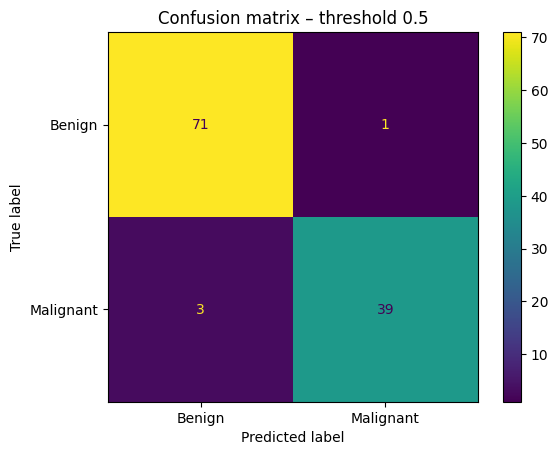

In [6]:
cm = confusion_matrix(y_test, pred_05, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix (rows=actual [benign, malignant], columns=predicted [benign, malignant]):")
display(pd.DataFrame(cm, index=["Actual benign (0)", "Actual malignant (1)"],
                    columns=["Predicted benign (0)", "Predicted malignant (1)"]))
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

metrics = {
    "Accuracy": accuracy_score(y_test, pred_05),
    "Precision": precision_score(y_test, pred_05, zero_division=0),
    "Recall / Sensitivity": recall_score(y_test, pred_05, zero_division=0),
    "Specificity": tn/(tn+fp) if (tn+fp) else np.nan,
    "F1-score": f1_score(y_test, pred_05, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, proba)
}
display(pd.DataFrame({"test_set_result": metrics}).round(4))
print(classification_report(y_test, pred_05, target_names=["Benign (0)", "Malignant (1)"], zero_division=0))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", "Malignant"]).plot()
plt.title("Confusion matrix – threshold 0.5"); plt.show()

### Metric formulas
- Accuracy = (TP + TN) / (TP + TN + FP + FN)
- Precision = TP / (TP + FP)
- Recall (sensitivity) = TP / (TP + FN)
- Specificity = TN / (TN + FP)
- F1-score = 2 × (Precision × Recall) / (Precision + Recall)
- ROC-AUC = area under the ROC curve; 0.5 is chance ranking and 1.0 is perfect ranking.

The baseline below always predicts the majority class from the training set. Accuracy alone can be misleading when classes are imbalanced, so recall, precision and ROC-AUC are also reported.

In [7]:
majority_class = int(y_train.value_counts().idxmax())
baseline_pred = np.full(len(y_test), majority_class)
baseline_accuracy = accuracy_score(y_test, baseline_pred)
print("Majority class in training data:", majority_class)
print("Baseline test accuracy:", round(baseline_accuracy, 4))
print("Logistic Regression test accuracy:", round(metrics["Accuracy"], 4))
print("Baseline classification report:")
print(classification_report(y_test, baseline_pred, target_names=["Benign (0)", "Malignant (1)"], zero_division=0))

Majority class in training data: 0
Baseline test accuracy: 0.6316
Logistic Regression test accuracy: 0.9649
Baseline classification report:
               precision    recall  f1-score   support

   Benign (0)       0.63      1.00      0.77        72
Malignant (1)       0.00      0.00      0.00        42

     accuracy                           0.63       114
    macro avg       0.32      0.50      0.39       114
 weighted avg       0.40      0.63      0.49       114



## 8. ROC curve and threshold comparison
ROC curve plots true-positive rate against false-positive rate at different thresholds. ROC-AUC measures ranking performance across thresholds. The threshold table shows how the number of predicted positive records and the precision/recall balance change at 0.3, 0.5 and 0.7.

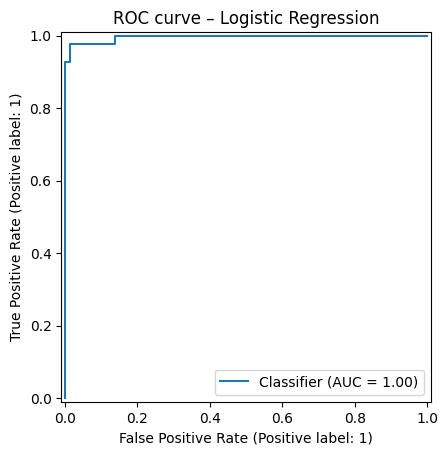

ROC-AUC: 0.996


,threshold,predicted_positive,accuracy,precision,recall,f1_score
0,0.3,42,0.9825,0.9762,0.9762,0.9762
1,0.5,40,0.9649,0.9750,0.9286,0.9512
2,0.7,38,0.9649,1.0000,0.9048,0.9500


In [8]:
RocCurveDisplay.from_predictions(y_test, proba)
plt.title("ROC curve – Logistic Regression")
plt.show()
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))

threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    pred = (proba >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "predicted_positive": int(pred.sum()),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1_score": f1_score(y_test, pred, zero_division=0)
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))

**Threshold recommendation:** for a screening-support demonstration, a lower threshold such as 0.3 may be considered when avoiding false negatives is the priority, because it generally increases sensitivity at the cost of more false positives. The final choice must be based on the actual threshold table and reviewed by qualified domain professionals. This coursework model is not suitable for real clinical decisions.

## 9. Decision behaviour visualisation
The plot below shows predicted malignant probability against one selected measurement (mean radius) for the test records. It is a one-feature view of a model that uses all 30 features; points can overlap because other measurements also affect the prediction.

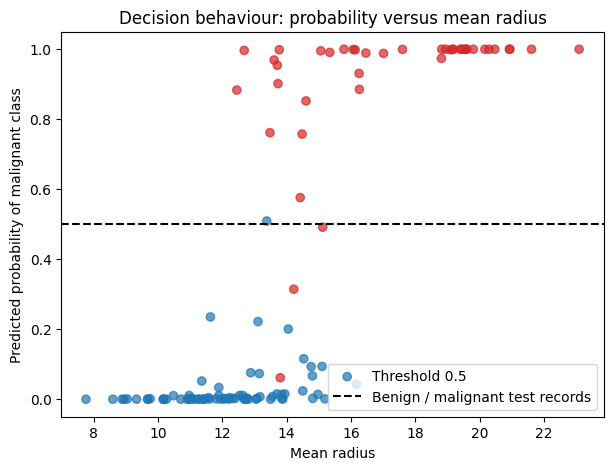

In [9]:
plt.figure(figsize=(7,5))
colors = np.where(y_test.to_numpy()==1, "tab:red", "tab:blue")
plt.scatter(X_test["mean radius"], proba, c=colors, alpha=0.7)
plt.axhline(0.5, color="black", linestyle="--", label="Threshold 0.5")
plt.xlabel("Mean radius"); plt.ylabel("Predicted probability of malignant class")
plt.title("Decision behaviour: probability versus mean radius")
plt.legend(["Threshold 0.5", "Benign / malignant test records"])
plt.show()

## 10. Train/test comparison and new example
Compare training and test metrics to identify possible overfitting. For a new example, use the median of the training features; this keeps the example within the general feature scale observed during training. The prediction is a probability-based estimate, not a guaranteed outcome.

In [10]:
train_proba = model.predict_proba(X_train)[:,1]
train_pred = (train_proba >= 0.5).astype(int)
train_test_comparison = pd.DataFrame({
    "training": {
        "accuracy": accuracy_score(y_train, train_pred),
        "precision": precision_score(y_train, train_pred, zero_division=0),
        "recall": recall_score(y_train, train_pred, zero_division=0),
        "F1": f1_score(y_train, train_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_train, train_proba)
    },
    "test": {
        "accuracy": accuracy_score(y_test, pred_05),
        "precision": precision_score(y_test, pred_05, zero_division=0),
        "recall": recall_score(y_test, pred_05, zero_division=0),
        "F1": f1_score(y_test, pred_05, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    }
})
display(train_test_comparison.round(4))

new_record = X_train.median().to_frame().T
new_probability = model.predict_proba(new_record)[0,1]
new_class = int(new_probability >= 0.5)
print("New example: median of training features")
display(new_record)
print(f"Predicted probability of malignant class: {new_probability:.4f}")
print("Predicted class:", "Malignant (1)" if new_class else "Benign (0)")

,training,test
accuracy,0.9868,0.9649
precision,1.0000,0.9750
recall,0.9647,0.9286
F1,0.9820,0.9512
ROC-AUC,0.9976,0.9960


New example: median of training features


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,13.34,18.9,86.18,546.4,0.09524,0.09228,0.0594,0.03334,0.1799,0.0613,0.3274,1.139,2.31,24.87,0.006261,0.02016,0.02586,0.01091,0.0187,0.003131,14.92,25.48,97.65,683.4,0.1311,0.2167,0.2298,0.101,0.2823,0.08009


Predicted probability of malignant class: 0.0476
Predicted class: Benign (0)


## 11. Decision log, limitations and conclusion
**Decision log**
1. Dataset: selected a public, labelled dataset with two classes and numerical features.
2. Class definition: remapped malignant to positive class 1 so that recall has a clear screening interpretation.
3. Preparation: used a stratified 80:20 split and fitted scaling on training data only.
4. Metric priority: recall is important because false negatives are more serious in a screening-support context; precision and specificity are also monitored.
5. Threshold: compare 0.3, 0.5 and 0.7 using the computed table rather than assuming 0.5 is always best.
6. Limitations: dataset and model are educational; predictions may be wrong, may not generalise to other populations or equipment, and must not be used for diagnosis.

**Conclusion:** Logistic Regression produces probabilities that can be converted into binary labels using a threshold. The confusion matrix and multiple evaluation metrics show different types of errors, while the threshold comparison makes the precision–recall trade-off visible. The model should only be treated as a coursework demonstration.

## References
1. Scikit-learn, *Breast cancer Wisconsin diagnostic dataset*: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
2. Scikit-learn, *LogisticRegression*: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
3. Scikit-learn, *Classification metrics*: https://scikit-learn.org/stable/modules/model_evaluation.html

**GitHub publication:** Create a separate public repository for this activity, include this notebook and a README, and add the course-provided reference link: https://github.com/complexiota